In [ ]:
# Imports
import numpy as np
import matplotlib.pyplot as plt
import multiprocessing as mp
import pickle
from statsmodels.nonparametric.smoothers_lowess import lowess

### Car class:

In [ ]:
class VehicleClass:
    def __init__(self, car_id, initial_pos, initial_vel, initial_acc, initial_headway, initial_dv, speedlim, acc_exp, time_gap, min_gap, comf_decel, acc_max, length):

        self.car_id = car_id

        self.pos = [initial_pos]
        self.vel = initial_vel
        self.acc = initial_acc

        self.headway = initial_headway
        self.dv = initial_dv

        self.prev_vel = initial_vel
        self.prev_acc = 0

        self.speedlim = speedlim
        self.des_speed = speedlim
        self.des_speed_inv = 1.0 / speedlim if speedlim > 0 else 0

        self.acc_exp = acc_exp
        self.time_gap = time_gap
        self.min_gap = min_gap
        self.comf_decel = comf_decel
        self.acc_max = acc_max

        self.length = length

    def update_cars(cars, time_step, L):

        # Update acc based on IDM
        acc_new = VehicleClass.calc_acc(cars)

        # Update velocity and position
        cars = VehicleClass.upd_pos_vel(cars, time_step, acc_new, L)

        cars = VehicleClass.update_headway_dv(cars, L, time_step)

        return cars

    def calc_acc(cars):

        acc_new = np.zeros(len(cars))

        for i, car in enumerate(cars):
            if car.car_id!= -1:

                # Calculate desired bumper-to-bumper distance (s*)
                s_star = car.min_gap + max(0, car.vel * car.time_gap + (car.vel * car.dv) / (2 * (car.acc_max * car.comf_decel)**0.5))

                # Calculate acceleration using IDM
                acc_new[i] = car.acc_max * (1 - (car.vel * car.des_speed_inv)**car.acc_exp - (s_star / (car.headway))**2)

        # Set new acceleration value
        return acc_new

    def upd_pos_vel(cars, time_step, acc_new, L):

        for i, car in enumerate(cars):
            if car.car_id!= -1:
                # Update velocity and position
                vel_new = car.vel + acc_new[i] * time_step

                t = time_step

                # Ensure velocity does not go negative
                if vel_new < 0:

                    # Calculate time to stop
                    t = -car.vel / acc_new[i]

                    vel_new = car.vel + acc_new[i] * t

                pos_new = (car.pos[-1] + car.vel * t + 0.5 * acc_new[i] * t**2) % L

                # Update values
                car.prev_vel = car.vel
                car.prev_acc = acc_new[i]
                car.acc = acc_new[i]
                car.vel = vel_new
                car.pos.append(pos_new)

        return cars

    def update_headway_dv(cars, L, time_step):

        for  i, car in enumerate(cars):
            if car.car_id!= -1:

                # Get next car
                index = (i + 1) % len(cars)
                next_car = cars[index]

                # Compute headway
                headway = ((next_car.pos[-1] - next_car.length) % L - car.pos[-1]) % L

                if headway < car.min_gap:

                    # Calculate desired bumper-to-bumper distance (s*)
                    s_star = car.min_gap

                    # Calculate acceleration using IDM
                    acc_new = car.acc_max * (1 - (car.prev_vel * car.des_speed_inv)**car.acc_exp - (s_star / (headway))**2)

                    # Update velocity and position
                    vel_new = car.prev_vel + acc_new * time_step

                    # Ensure velocity does not go negative
                    if vel_new < 0:

                        # Calculate time to stop
                        t_stop = -car.prev_vel / acc_new

                        vel_new = car.prev_vel + acc_new * t_stop

                    # Update acceleration and velocity
                    car.acc = acc_new
                    car.vel = vel_new

        for i, car in enumerate(cars):
            if car.car_id!= -1:
                next_car = cars[(i + 1) % len(cars)]
                headway = ((next_car.pos[-1] - next_car.length) % L - car.pos[-1]) % L

                car.headway = headway
                car.dv = car.vel - next_car.vel

        return cars

### Traffic Light Class:

In [ ]:
class TrafficLightClass:
    def __init__(self, position, green_duration, orange_duration, red_duration, initial_state="green"):
        self.position = position
        self.green_duration = green_duration
        self.orange_duration = orange_duration
        self.red_duration = red_duration
        self.current_state = initial_state
        self.time_in_state = 0
        self.total_time = 0

    def update(self, time_step):
        self.time_in_state += time_step
        self.total_time += time_step

        if self.current_state == "green" and self.time_in_state >= self.green_duration and self.green_duration != 120:
            self.current_state = "orange"
            self.time_in_state = 0
        elif self.current_state == "orange" and self.time_in_state >= self.orange_duration:
            self.current_state = "red"
            self.time_in_state = 0
        elif self.current_state == "red" and self.time_in_state >= self.red_duration and self.red_duration != 120:
            self.current_state = "green"
            self.time_in_state = 0

    def status(self):
        return self.current_state

    def time_in_current_state(self):
        return self.time_in_state

### Simulation Functions:

In [ ]:
def init_simulation(N, L,):

    cars = []
    initial_vel = 0
    initial_acc = 0
    dv = 0
    length = 5
    min_gap = 2
    acc_exp = 4
    time_gap = 1
    comf_decel = 1.5
    acc_max = 1
    speed_limit = 70 / 2.237

    # Set initial positions
    pos = np.zeros(N)
    for i in range(N):
        pos[i] = i * (length + min_gap)

    # Ensure the minimum gap is maintained
    while True:

        changes = False

        # Loop to adjust positions
        for i in range(N):

            # Next car index
            j = (i + 1) % N

            # Compute headway
            headway = ((pos[j] - length) % L - pos[i]) % L

            # Ensure minimum gap is maintained (remove this?)
            if headway < min_gap:

                changes = True

                # Move the car back to maintain the minimum gap
                pos[i] = ((pos[j] - length) % L - min_gap) % L

        if not changes:
            break

    # Create cars
    for i in range(N):

        next_car = (i + 1) % N
        headway = ((pos[next_car] - length) - pos[i]) % L

        car = VehicleClass(i, pos[i], initial_vel, initial_acc, headway, dv, speed_limit, acc_exp, time_gap, min_gap, comf_decel, acc_max, length)
        cars.append(car)

    return cars

def flow_global(N, velocities, L):

    # Calculate global density (cars per km)
    dens = N / (L / 1000)

    # Calculate avergae velocity
    avg_vel = np.mean(velocities)

    # Calculate global flow (cars per hour)
    flow = dens * avg_vel * 3.6

    return dens, flow

def analyse_global(track_flow, track_dens):

    # Calculate overall global flow and density
    glob_flow = np.mean(track_flow)
    glob_dens = np.mean(track_dens)

    return glob_flow, glob_dens

def analyse_local(track_det_time, track_det_vel, time):

    # Avoid division by zero if no detection data
    if not track_det_time or not track_det_vel:
        return 0, 0

    num_cars = len(track_det_time)

    # Calculate local flow
    loc_flow = (num_cars / time) * 3600

    # Calculate local density
    avg_speed = sum(track_det_vel) / num_cars
    loc_dens = loc_flow / (avg_speed * 3.6)

    return loc_flow, loc_dens

def add_phantom_car(cars, traffic_light, L):

    # Get the traffic light position
    light_pos = traffic_light.position

    # Create phantom car at traffic light position
    phantom_car = VehicleClass(-1, light_pos, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 10)

    cars.sort(key=lambda car: car.pos[-1])

    for i in reversed(range(len(cars))):

        car = cars[i]

        # Check if car can make it through
        s = (phantom_car.pos[-1] - car.pos[-1]) % L

        max_s = car.vel * (traffic_light.orange_duration - traffic_light.time_in_state)

        if max_s <= s and car.pos[-1] <= phantom_car.pos[-1]:

            cars.insert(i + 1, phantom_car)
            break

    return cars

def remove_phantom_car(cars, L):

    new_cars = []

    for i, car in enumerate(cars):

        next_car = cars[(i + 1) % len(cars)]

        if next_car.car_id == -1:
            next_car = cars[(i + 2) % len(cars)]
            car.headway = ((next_car.pos[-1] - next_car.length) % L - car.pos[-1]) % L
            car.dv =   car.vel - next_car.vel

        if car.car_id != -1:
            new_cars.append(car)
        else:
            del(car)

    new_cars.sort(key=lambda car: car.pos[-1])

    return new_cars

def get_headway(cars, L):

    for i in range(len(cars)):

        # Check if the current car is a phantom car
        if cars[i].car_id == -1:

            # Get the next car and previous car
            car = cars[i]
            next_car = cars[(i + 1) % len(cars)]
            prev_car = cars[(i - 1) % len(cars)]

            # Calculate headway between previous car and next car and traffic light
            headway_prev = ((car.pos[-1] - car.length) % L - prev_car.pos[-1]) % L
            headway_next = ((next_car.pos[-1] - next_car.length) % L - prev_car.pos[-1]) % L

            # Set to min headway
            prev_car.headway = min(headway_prev, headway_next)

            # Check if dv is needed to be updated
            if prev_car.headway == headway_next:
                prev_car.dv = prev_car.dv - next_car.dv
            break

    return cars

def Step(N, cars, time_pass, time_measure, det_point, L, time_step, traffic_light):

    # Measurement variables
    den = 0
    flo = 0
    detect_time = []
    detect_vel = []
    time_left = traffic_light.orange_duration - traffic_light.time_in_state

    # Update traffic light state
    traffic_light.update(time_step)
    light_state = traffic_light.status()


    # Handle state transitions
    if light_state == 'red' and len(cars) == N:
        cars = add_phantom_car(cars, traffic_light, L)
    if light_state == 'orange' and time_left > 4:
        cars = remove_phantom_car(cars, L)
        cars = add_phantom_car(cars, traffic_light, L)
    elif light_state == 'green' and len(cars) > N:
        cars = remove_phantom_car(cars, L)

    if light_state == 'orange':
        cars = get_headway(cars, L)

    cars.sort(key=lambda car: car.pos[-1])

    cars = VehicleClass.update_cars(cars, time_step, L)

    # Take measurements
    if time_pass > time_measure:
        den, flo = flow_global(N, [car.vel for car in cars if car.car_id != -1], L)

        # Detection loop for local measurements
        for car in cars:
            if car.car_id != -1:
                if (car.pos[-2] < det_point <= car.pos[-1]) or (car.pos[-1] < car.pos[-2] and (car.pos[-2] < det_point <= car.pos[-1] + L)):

                    # Calculate distance from initial position to detection point
                    s = det_point - car.pos[-2]

                    # Calculate delta t
                    if car.prev_acc == 0:
                        delta_t = s / car.prev_vel if car.prev_vel != 0 else 0
                    else:
                        sqrt_term = car.prev_vel**2 + 2 * car.prev_acc * s
                        delta_t = (-car.prev_vel + np.sqrt(sqrt_term)) / car.prev_acc

                    # Store detection time and velocity
                    detect_time.append(time_pass - time_step + delta_t)
                    detect_vel.append(car.prev_vel + car.prev_acc * delta_t)

    return cars, den, flo, detect_time, detect_vel

def Simulate_IDM(N, time_step, steps, steps_measure, det_point, L, traffic_light):

    # Declare variables
    track_flow = []
    track_dens = []
    track_det_time = []
    track_det_vel = []

    # Initialise cars
    cars = init_simulation(N, L)

    for i in range(steps):

        time_pass = i * time_step

        cars, den, flo, detect_time, detect_vel = Step(N, cars, time_pass, steps_measure * time_step, det_point, L, time_step, traffic_light)

        if time_pass > steps_measure * time_step:
            track_flow.append(flo)
            track_dens.append(den)
            track_det_time.extend(detect_time)
            track_det_vel.extend(detect_vel)

    glob_flow, glob_dens = analyse_global(track_flow, track_dens)
    loc_flow, loc_dens = analyse_local(track_det_time, track_det_vel, steps * time_step)

    print('Simulation for green duration =', traffic_light.green_duration, 'completed')

    cars = remove_phantom_car(cars, L)

    return cars, glob_flow, glob_dens, loc_flow, loc_dens

### Main:

In [ ]:
def run_simulation(N, time_step, steps, steps_before_measure, detection_point, road_length, traffic_light):

    cars, glob_flow, glob_density, loc_flow, loc_dens = Simulate_IDM(N, time_step, steps, steps_before_measure, detection_point, road_length, traffic_light)

    glob_avg_velocity = (glob_flow * 1000) / (glob_density * 3600) if glob_density != 0 else 0
    loc_avg_velocity = (loc_flow * 1000) / (loc_dens * 3600) if loc_dens != 0 else 0

    return N, cars, glob_flow, glob_density, loc_flow, loc_dens, glob_avg_velocity, loc_avg_velocity

def make_traffic_light(L, green_duration, ss):
    cycle_time = 120
    orange_time = 20

    if green_duration == 0:
        orange_time = 0
        ss = 'red'
    elif green_duration == 100:
        orange_time = 0
        green_duration = 120

    return TrafficLightClass(L / 2, green_duration, orange_time, cycle_time - (green_duration + orange_time), ss)

if __name__ == "__main__":

    # Model parameters
    number_of_cars = 60
    road_length = 500
    steps = 10000
    steps_before_measure = 100
    detection_point = road_length / 2
    time_step = 0.5
    gd1 = np.linspace(0, 100, 40)

    gd1 = [gd if gd < 100 else 120 for gd in gd1]

    with mp.Pool(processes=mp.cpu_count()) as pool:
        results = pool.starmap(run_simulation, [(number_of_cars, time_step, steps, steps_before_measure, detection_point, road_length, make_traffic_light(road_length, gd, 'green')) for gd in gd1])

    # Write data to file
    print("Writing file...")

    global_flow, local_flow = [], []
    global_density, local_density = [], []
    global_average_velocity, local_average_velocity = [], []
    cars_positions = []

    global_flow2, local_flow2 = [], []
    global_density2, local_density2 = [], []
    global_average_velocity2, local_average_velocity2 = [], []
    cars_positions2 = []

    for _, car_list, g_flow, g_density, l_flow, l_density, g_avg_vel, l_avg_vel in results:
        global_flow.append(g_flow)
        global_density.append(g_density)
        local_flow.append(l_flow)
        local_density.append(l_density)
        global_average_velocity.append(g_avg_vel)
        local_average_velocity.append(l_avg_vel)
    cars_positions.append([car.pos for car in car_list])

    # Organise data into a dictionary
    simulation_data = {
        "cars_positions": cars_positions,
        "road_length": road_length,
        "global_density": global_density,
        "global_flow": global_flow,
        "local_density": local_density,
        "local_flow": local_flow,
        "global_average_velocity": global_average_velocity,
        "local_average_velocity": local_average_velocity,
        "green_durations": gd1
    }

    # Save using pickle with highest protocol for speed optimisation
    with open('simulation_results_traffic_system.pkl', 'wb') as file:
        pickle.dump(simulation_data, file, protocol=pickle.HIGHEST_PROTOCOL)

    print("File writing complete.")

Simulation for green duration = 12.820512820512821 completed
Simulation for green duration = 0.0 completed
Simulation for green duration = 15.384615384615387 completed
Simulation for green duration = 2.5641025641025643 completed
Simulation for green duration = 17.94871794871795 completed
Simulation for green duration = 5.128205128205129 completed
Simulation for green duration = 20.512820512820515 completed
Simulation for green duration = 7.692307692307693 completed
Simulation for green duration = 23.07692307692308 completed
Simulation for green duration = 10.256410256410257 completed
Simulation for green duration = 25.641025641025642 completed
Simulation for green duration = 38.46153846153847 completed
Simulation for green duration = 28.205128205128208 completed
Simulation for green duration = 41.02564102564103 completed
Simulation for green duration = 30.769230769230774 completed
Simulation for green duration = 43.58974358974359 completed
Simulation for green duration = 33.33333333333

### Plotting Without Running Simulation:

<ipython-input-7-878ff00848e9>:24: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticks(), fontsize=25)
<ipython-input-7-878ff00848e9>:25: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(ax.get_yticks(), fontsize=25)


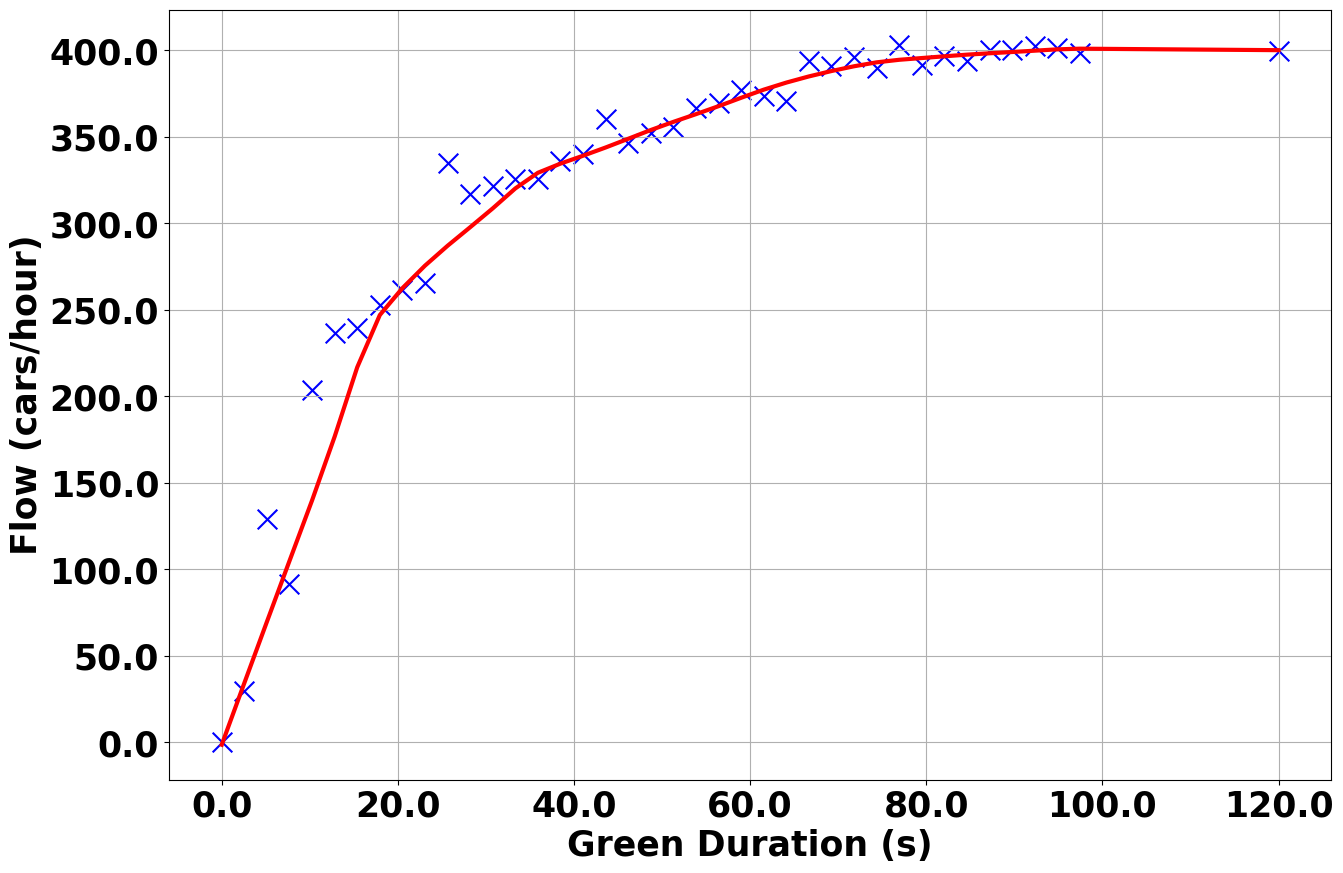

In [ ]:
def load_results(filename):

    with open(filename, 'rb') as file:
        return pickle.load(file)

def plot_graph(ax, x, y, xlabel, ylabel, color, marker='0'):

    # Scatter plot
    ax.scatter(x, y, color=color, marker='x', s= 200)

    # LOWESS smoothing for best-fit line
    smoothed = lowess(y, x, frac=0.32)
    ax.plot(smoothed[:, 0], smoothed[:, 1], 'r-', lw=3)

    # Formatting
    ax.set_xlabel(xlabel, fontsize=25, weight='bold')
    ax.set_ylabel(ylabel, fontsize=25, weight='bold')

    for tick in ax.get_xticklabels():
        tick.set_fontweight('bold')
    for tick in ax.get_yticklabels():
        tick.set_fontweight('bold')

    ax.set_xticklabels(ax.get_xticks(), fontsize=25)
    ax.set_yticklabels(ax.get_yticks(), fontsize=25)
    ax.grid(True)

results = load_results('simulation_results_traffic_system.pkl')
data = {key: results.get(key, []) for key in ['cars_positions', 'road_length', 'global_density', 'global_flow', 'local_density', 'local_flow', 'global_average_velocity', 'local_average_velocity', 'green_durations']}

# Basic plots
fig1, axes1 = plt.subplots(1, 1, figsize=(15, 10))
plot_graph(axes1, data['green_durations'], data['local_flow'], 'Green Duration (s)', 'Flow (cars/hour)', 'blue')

plt.savefig('durations_plot.png')